# Data Preparation

In [1]:
import torch
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import ast

import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.autonotebook import tqdm

from hgctsvg.preprocessing import st, kidneycancer

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFou

Identify source and results directories

In [2]:
results_dir = Path("hgctsvg_project_files")
project_name = "Human Kidney Cancer Interface"

project_files_dir = results_dir / project_name
project_files_dir.mkdir(parents=True, exist_ok=True)

In [3]:
spotiphy_proj_dir = Path("spotiphy_project_files") / project_name

Load deconvolution results and spatial transcriptomics data.

Spatial transcriptomics data contains spot ids and spot locations, which are requirements for creating hyperedges.

In [4]:
adata_decomp = sc.read_h5ad(spotiphy_proj_dir / "ST_decomposition.h5ad")
adata_st = sc.read_h5ad(spotiphy_proj_dir / "Human Kidney Cancer Interface.h5ad")

Load *n_cell_df.csv*.  This file contains nucleuse indices, nucleus centers, and cell counts per spot.

Note: Based on the information provided by *n_cell_df.csv*, Spotiphy predicts the number of cells of each type in a spot. However, identifying which of the cells are of the given types is a random guess.

In [5]:
# Cell df contains nucleus indices, nucleus centers, and cell counts per spots
cell_df = pd.read_csv(spotiphy_proj_dir / "segmentation" / "n_cell_df.csv",
                     index_col=0)

Load segmentation results.

Segmentation results contain cells' membership to spots, tissue location, and cell boundaries, which are important in visualization.

In [6]:
# Load segmentation boundary
segmentation_boundary = np.load(spotiphy_proj_dir / "segmentation" / "segmentation_boundary.npy", allow_pickle=True)
segmentation_boundary.shape

(60995, 32, 2)

In [7]:
# Extract nucleus centers and cell boundaries from the segmentation results.
cell_centers = np.empty((adata_decomp.n_obs, 2), dtype=float)
cell_boundaries = np.empty((adata_decomp.n_obs,32,2), dtype=float)

for i in range(adata_st.n_obs):
    cell_count = cell_df['cell_count'][i]
    if cell_count == 0:
        continue
    nucleus_indices = ast.literal_eval(cell_df['Nucleus indices'][i])
    nucleus_centers = ast.literal_eval(cell_df['Nucleus centers'][i])
    nucleus_centers = np.array(nucleus_centers)
    cell_boundary_x = segmentation_boundary[nucleus_indices][:,:,0]
    cell_boundary_y = segmentation_boundary[nucleus_indices][:,:,1]
    
    # nucleus_centers_df = pd.DataFrame(nucleus_centers, columns=["nucleus_x", "nucleus_y"])

    cell_indexes = adata_decomp[adata_decomp.obs["spot_name"] == adata_st.obs_names[i]].obs_names
    cell_centers[cell_indexes.values.astype(int)] = nucleus_centers
    cell_boundaries[cell_indexes.values.astype(int)] = segmentation_boundary[nucleus_indices]
    # print(cell_boundary_x)
    # cell_topology.loc[cell_indexes, "boundary_x"] = cell_boundary_x
    # cell_topology.loc[cell_indexes, "boundary_y"] = cell_boundary_y

In [8]:
adata_decomp.obsm['cell_nucleus'] = cell_centers
adata_decomp.obsm['cell_boundaries'] = cell_boundaries
adata_decomp.obsm['cell_nucleus'].shape, adata_decomp.obsm['cell_boundaries'].shape

((22430, 2), (22430, 32, 2))

Assign the nucleus location as the location of each cell. 

Squidpy's plotting functions require the input data to have the spatial metadata ` adata_decomp.obsm['spatial'] `.

In [9]:
adata_decomp

AnnData object with n_obs × n_vars = 22430 × 10867
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y'
    uns: 'cell_count', 'sample_colors', 'spatial'
    obsm: 'cell_nucleus', 'cell_boundaries'

In [44]:
np.unique(adata_decomp.obs['location_x']).shape, np.unique(adata_decomp.obs['location_y']).shape

((366,), (218,))

In [52]:
adata_decomp[adata_decomp.obs['spot_name'] == '6800STDY12499411_AACAATACATTGTCGA-1'].obs

,cell_type,spot_name,n_cell,location_x,location_y
0,B-cell,6800STDY12499411_AACAATACATTGTCGA-1,1,3511,7196
156,EC,6800STDY12499411_AACAATACATTGTCGA-1,3,3511,7196
157,EC,6800STDY12499411_AACAATACATTGTCGA-1,3,3511,7196
158,EC,6800STDY12499411_AACAATACATTGTCGA-1,3,3511,7196
4356,Epi_non-PT,6800STDY12499411_AACAATACATTGTCGA-1,1,3511,7196
6659,Fibro,6800STDY12499411_AACAATACATTGTCGA-1,2,3511,7196
6660,Fibro,6800STDY12499411_AACAATACATTGTCGA-1,2,3511,7196
9039,Myeloid,6800STDY12499411_AACAATACATTGTCGA-1,1,3511,7196
14085,Plasma,6800STDY12499411_AACAATACATTGTCGA-1,1,3511,7196
14640,RCC,6800STDY12499411_AACAATACATTGTCGA-1,2,3511,7196


In [53]:
adata_decomp[adata_decomp.obs['spot_name'] == '6800STDY12499411_AACAATACATTGTCGA-1'].obsm['spatial']

ArrayView([[3508., 7226.],
           [3540., 7210.],
           [3516., 7192.],
           [3502., 7200.],
           [3516., 7212.],
           [3498., 7182.],
           [3530., 7208.],
           [3484., 7192.],
           [3516., 7178.],
           [3536., 7180.],
           [3508., 7170.]])

In [10]:
adata_decomp.obsm['spatial'] = adata_decomp.obsm['cell_nucleus']

Type list is an array of all cell types in the tissue, sorted alphabetically.

Cell type mapping is a mapping of cell type names (string) to their position in type list (integer). Cell type mapping will be used in preparing datasets for the ML pipeline.

In [11]:
type_list, cell_type_mapping = kidneycancer.create_cell_type_mapping(adata_decomp)
# type_list, cell_type_mapping

Visualize distribution of each cell type within the tissue.

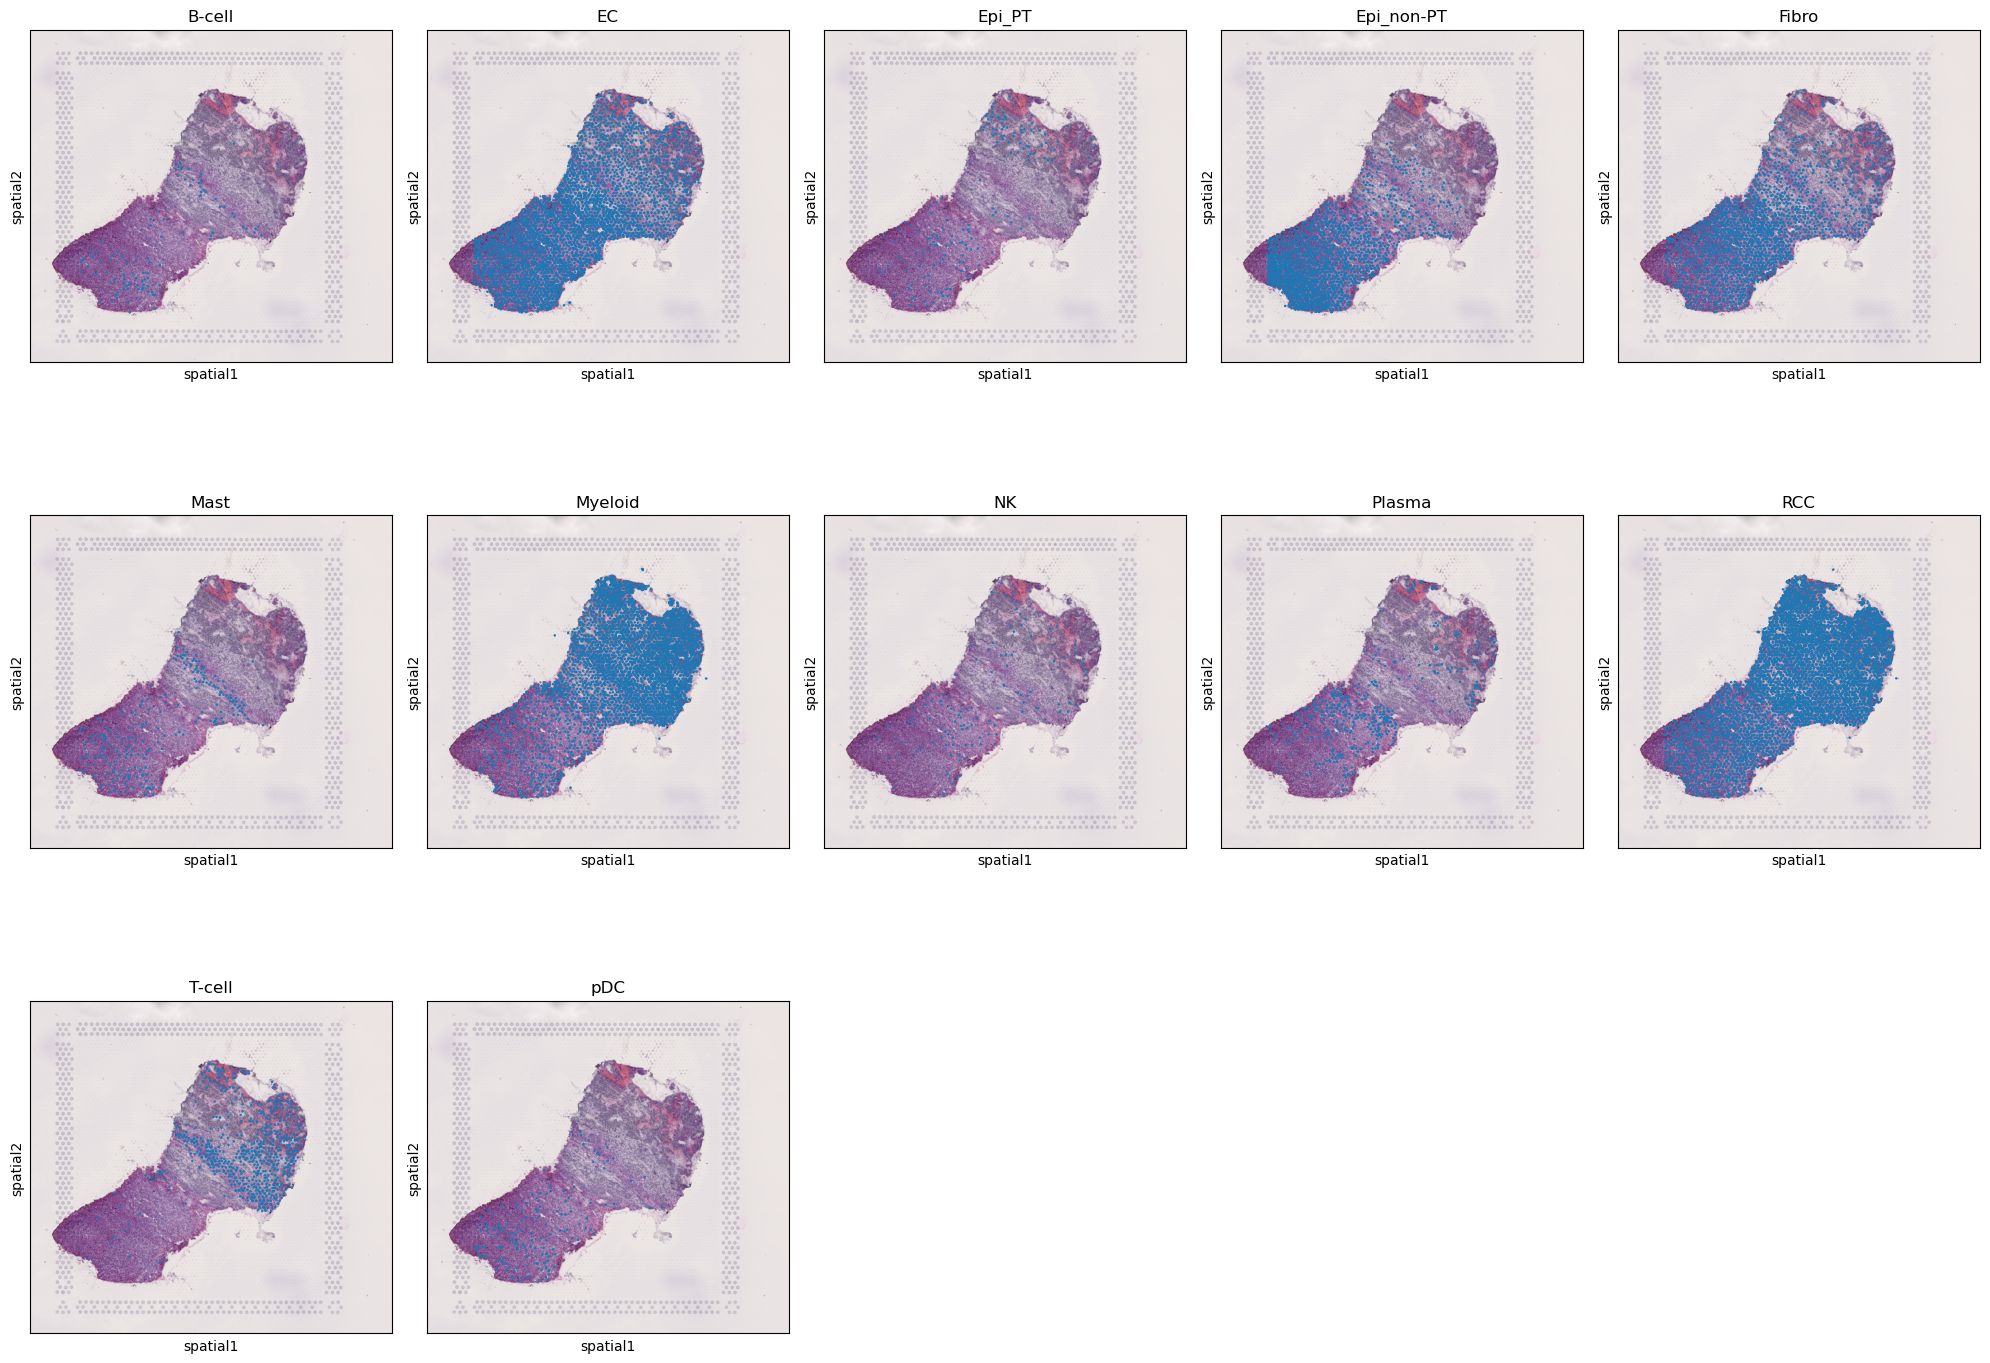

In [12]:
from hgctsvg.visualization import plot_ct_decomposition
plot_ct_decomposition(adata_decomp, 'cell_type', n_cols=5)

Preprocess original and decomposed ST data.

In [13]:
n_top_genes = 3000
sc.pp.log1p(adata_decomp)
sc.pp.log1p(adata_st)
sc.pp.highly_variable_genes(adata_decomp, n_top_genes=n_top_genes)
sc.pp.highly_variable_genes(adata_st, n_top_genes=n_top_genes)

In [14]:
st_hvgs = adata_st.var[adata_st.var["highly_variable"]].index
decomp_hvgs = adata_decomp.var[adata_decomp.var["highly_variable"]].index

In [15]:
common_hvgs = decomp_hvgs.intersection(st_hvgs)

In [16]:
adata_st = adata_st[:, common_hvgs.values]
adata_decomp = adata_decomp[:,decomp_hvgs.values]

In [17]:
common_hvgs.shape

(665,)

In [18]:
from hgctsvg.data import STHypergraphData

cell_feats, hyperedge_feats, cell_to_spot_id, cell_type, hyperedge_index, incidence_matrix, n_cell_types, n_spots = kidneycancer.create_hypergraph_data(adata_decomp, adata_st, num_neighbor_spots=7)

hgdata = STHypergraphData(cell_feats,
                          hyperedge_feats,
                          cell_to_spot_id,
                          cell_type,
                          hyperedge_index,
                          incidence_matrix,
                          n_cell_types,
                          n_spots)

hgdata.save(project_files_dir)

In [19]:
adata_st.obs

,in_tissue,array_row,array_col,sample,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,mt_frac,donor_id,region
spot_id,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,1,50,102,6800STDY12499411,4778,8.471987,14815.0,9.603463,27.046912,35.227810,44.414445,56.179548,0.099426,PD47171,g
6800STDY12499411_AAACACCAATAACTGC-1,1,59,19,6800STDY12499411,1536,7.337588,2822.0,7.945555,27.250177,36.463501,46.172927,63.288448,0.105245,PD47171,g
6800STDY12499411_AAACATGGTGAGAGGA-1,1,62,0,6800STDY12499411,2243,7.716015,4582.0,8.430109,28.000873,35.050196,44.107377,59.340899,0.165430,PD47171,g
6800STDY12499411_AAACCGGGTAGGTACC-1,1,42,28,6800STDY12499411,2555,7.846199,4903.0,8.497807,19.620640,28.696716,38.894554,53.885376,0.044463,PD47171,g
6800STDY12499411_AAACCGTTCGTCCAGG-1,1,52,42,6800STDY12499411,1277,7.153052,2113.0,7.656337,22.432560,32.465689,43.965925,63.227638,0.034548,PD47171,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,1,24,64,6800STDY12499411,3235,8.082093,8386.0,9.034438,25.518722,36.358216,46.255664,59.372764,0.061770,PD47171,g
6800STDY12499411_TTGTTGTGTGTCAAGA-1,1,31,77,6800STDY12499411,4374,8.383662,12266.0,9.414668,22.215881,31.664764,41.415294,54.345345,0.036116,PD47171,g
6800STDY12499411_TTGTTTCACATCCAGG-1,1,58,42,6800STDY12499411,1328,7.192182,2317.0,7.748460,23.910229,34.570565,45.576176,64.264135,0.015537,PD47171,g


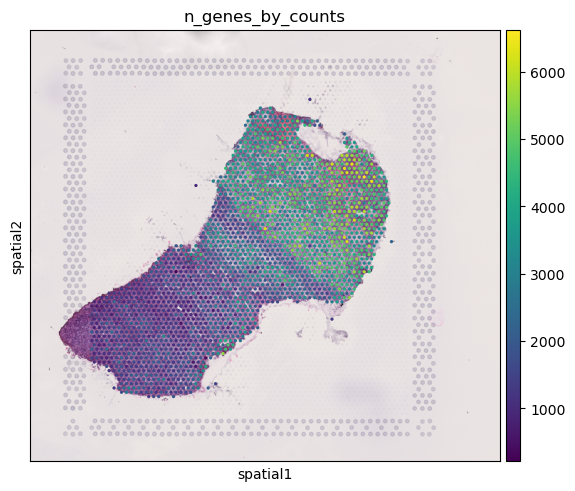

In [20]:
sq.pl.spatial_scatter(
        adata_st,
        # adata_decomp[adata_decomp.obs['cell_type'] == cell_type],
        color="n_genes_by_counts", # or a gene name
        title="n_genes_by_counts",
        legend_loc=None
)

In [21]:
adata_decomp.n_obs

22430

In [22]:
x = torch.tensor([[0,1,0,0,0],[0,0,0,1,0],[1,1,0,1,0]])

In [23]:
x.any(dim=1).nonzero(as_tuple=True)[0]

tensor([0, 1, 2])

In [24]:
# save adata_st
adata_st.write_h5ad(project_files_dir / "ST_init.h5ad")

# save adata_decomp
adata_decomp.write_h5ad(project_files_dir / "ST_decomposition.h5ad")

# save type list
typelist_np = np.array(type_list, dtype=str)
np.savetxt(project_files_dir / 'cell_types.txt',
           typelist_np,
           fmt='%s',
           delimiter='\n')

# HGCTSVG Pipeline

For each step of the pipeline, run the following commands:

## I. Embedding Learning

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg train-embedder --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg train-embedder --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## II. Embedding Generation

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg make-embedding --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg make-embedding --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## III. Spatial Domain Identification

```bash
hgctsvg compute-spatial-domains --project "Human Kidney Cancer Interface" 
```

## IV. Cell-type Specific Domain Identification

```bash
hgctsvg compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" \
--data.cell-type-key "cell_type"
```

## V. Classifier Training

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg train-celltype-domain-classifiers --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg train-classifier --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainr.accelerator cpu
```

## VI. Spatial Metagene Computation

### A. Compute Metagene Attribution to a Cell Type Spatial Domain
```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" \
--cell_type EC \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--attribution.n_steps 1000 --attribution.accelerator cuda
```

```bash
# Using CPU
hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" \
--cell_type EC \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--attribution.n_steps 1000 --attribution.accelerator cpu
```

### B. Compute Gene Attribution to Metagene

In [25]:
adata_st_clusters = sc.read_h5ad(project_files_dir / "clustering" / "ST_init.h5ad")
adata_st_clusters

AnnData object with n_obs × n_vars = 2048 × 665
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'leiden'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'leiden', 'log1p', 'neighbors', 'sample_colors', 'spatial'
    obsm: 'embedding', 'spatial'
    obsp: 'connectivities', 'distances'

```bash
CUDA_VISIBLE_DEVICES=0 hgctsvg train-embedder --project "Human Kidney Cancer Interface" --model.model-name CTHyFiEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
CUDA_VISIBLE_DEVICES=0 hgctsvg make-embedding --project "Human Kidney Cancer Interface" --model.model-name CTHyFiEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
# hgctsvg compute-spatial-domains --project "Human Kidney Cancer Interface"
hgctsvg compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" --data.cell-type-key "cell_type"
CUDA_VISIBLE_DEVICES=0 hgctsvg train-celltype-domain-classifiers --project "Human Kidney Cancer Interface" --classifier.embedding-dim 200 --classifier.num_layers 3 --trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-celltype-domain-attribution --project "Human Kidney Cancer Interface" --cell-type EC --model.model-name SpatialFusionEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.batch-size 8192 --explainer.accelerator cuda

# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-metagene-to-region-attribution --project "Human Kidney Cancer Interface" --cell-type EC --region 0 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-cell-metagene-attribution --project "Human Kidney Cancer Interface" --model.model-name SpatialFusionEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

```

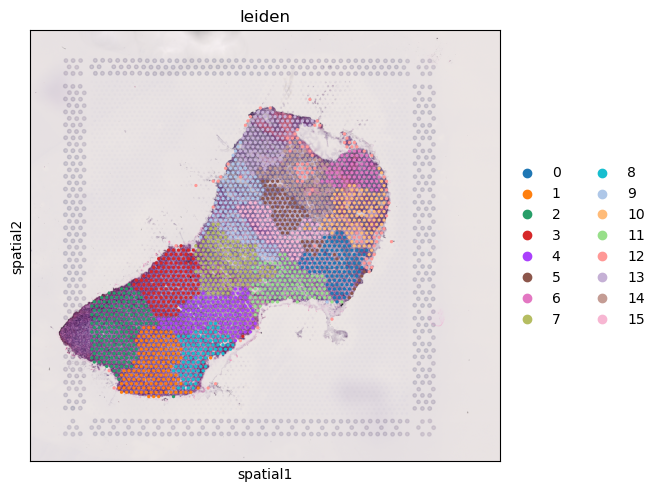

In [26]:
sq.pl.spatial_scatter(adata_st_clusters, spatial_key='spatial', color='leiden')

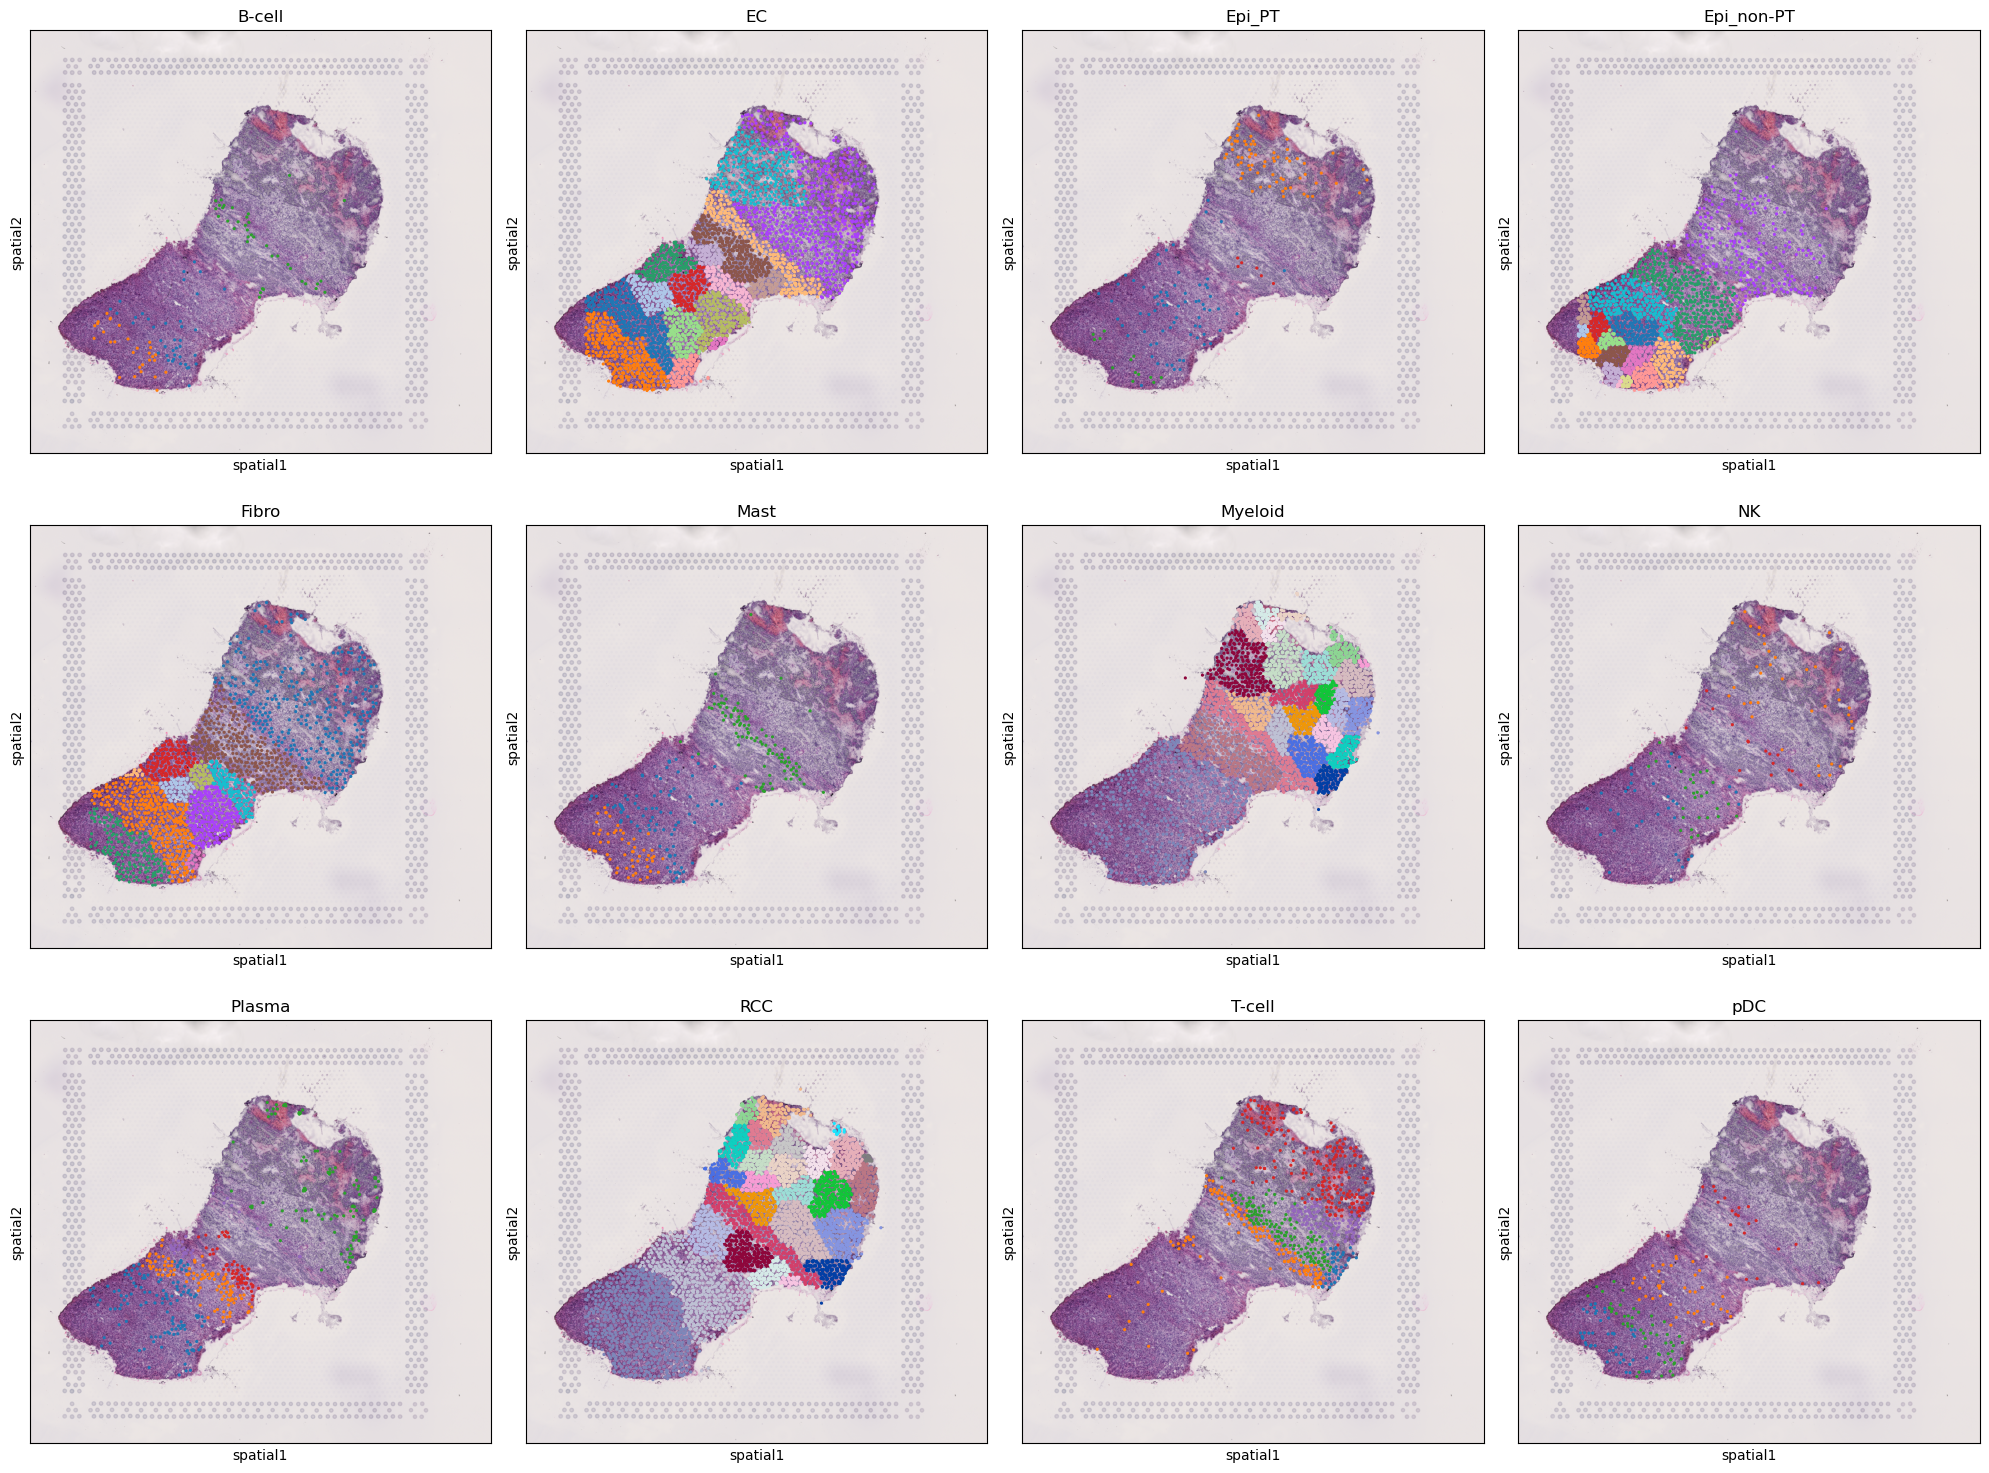

In [27]:
from hgctsvg.visualization import plot_ct_domains

plot_ct_domains(project_files_dir)

In [28]:
adata_EC = sc.read_h5ad(project_files_dir / "clustering" / "ST_cell_EC.h5ad")
adata_EC

AnnData object with n_obs × n_vars = 4026 × 3000
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_count', 'hvg', 'leiden', 'log1p', 'neighbors', 'sample_colors', 'spatial'
    obsm: 'cell_boundaries', 'cell_nucleus', 'embedding', 'spatial'
    obsp: 'connectivities', 'distances'

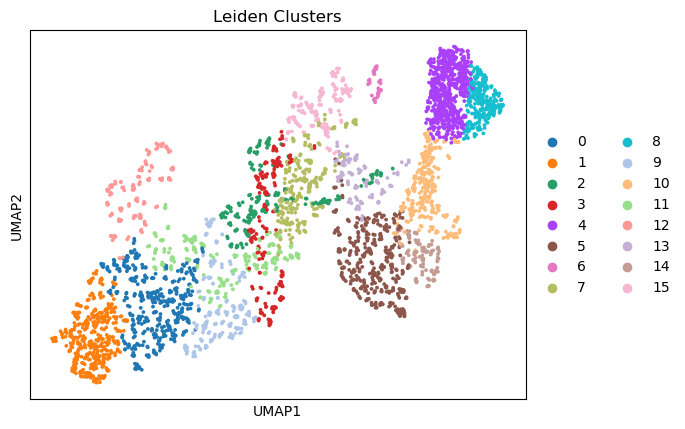

In [29]:
from scipy import sparse

sc.pp.neighbors(adata_EC, use_rep='embedding', knn=False, method='gauss', key_added='umap')
adata_EC.obsp['connectivities'] = sparse.csr_matrix(adata_EC.obsp['connectivities'])
sc.tl.umap(adata_EC)
sc.pl.umap(adata_EC, color='leiden', title='Leiden Clusters')

In [30]:
attributions_EC_dict = np.load(project_files_dir / "attribution" / "cell_type_EC" / "top_genes.npz")
attributions_EC_mean = attributions_EC_dict["mean_per_label"]
attributions_EC_all = attributions_EC_dict['attributions']
attributions_EC_all

array([[ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  0., ..., -0.,  0.,  0.],
       [ 0.,  0.,  0., ..., -0.,  0.,  0.],
       [ 0.,  0.,  0., ..., -0.,  0.,  0.]], dtype=float32)

In [31]:
adata_EC.X.max()

10.501833948767427

In [32]:
attributions_EC_mean.shape

(16, 3000)

In [33]:
from hgctsvg.pipeline import Explainer

gene_idx = Explainer(project_files_dir).find_domain_gene_idx("EC", alpha=2.5)

16
[0 0 0 ... 2 2 2]
(4026, 3000) (4026,)
(426, 3000)
(400, 3000)
(200, 3000)
(187, 3000)
(629, 3000)
(386, 3000)
(37, 3000)
(254, 3000)
(269, 3000)
(201, 3000)
(287, 3000)
(215, 3000)
(149, 3000)
(112, 3000)
(110, 3000)
(164, 3000)


In [34]:
for i, idx in enumerate(gene_idx):
    print(i, idx)

0 [1469 1219  576  742 1002  723 2509  134 1192 1890 2517  446 2014 2475
 1920  881  303 2030 1580  328 2237 1441  709 1088 1540 2983 2535 1934
 2195 2562  608  525 2538 2987  455  319  427 2850 1740  433  651 2381
 2294 1749 1367 2166 2764  287 1199 1083 1350 2008 2755 2545  957 1939
 2176 2927 2211   11 1562 2222 2246 1638  736  949 1971 2774 1629 2770
 1970 2679  670 2813 1076 1052  216 1097 1503 2738 1786 2446 1858 2405
 2300 2837  444  827 1847 2281 2059  233  769 1294 1798 2121  502 1343
 1961  343 2458 1174  564 1842 1263 1279 1613]
1 [ 601 1213 2266 1938 2414  132 1358  258 1542  683 2814 2889 2980  774
  798 1120 1432 2668 2027  904 2700  596  742 2844 2271 2137 1753 2399
 1922 1335 2134 1076 1852 1818 1057  769  982 2208   93 2780 1219 1326
 1516  858 1369   23 2896 2699 2018 2095 2537 1052 1756 1185 1967  234
 1832 1920  880 2186 1785 2986  684 1831 1431  972 2439 2259  400 2653
 2405 2311 1041 1586 2356 1734 1418 2206 2026  252 2596  792 1345  378
  786 2900 1009 1698  202 

In [35]:
from functools import reduce

all_genes = reduce(np.union1d, gene_idx)
all_genes

array([   1,    9,   10,   11,   17,   20,   21,   23,   25,   29,   31,
         34,   54,   58,   61,   66,   67,   72,   79,   93,   96,  100,
        104,  107,  108,  119,  124,  125,  128,  130,  132,  134,  138,
        141,  144,  153,  154,  174,  175,  177,  179,  181,  182,  192,
        200,  202,  208,  213,  216,  221,  223,  226,  228,  232,  233,
        234,  248,  252,  258,  264,  265,  269,  275,  277,  279,  282,
        283,  286,  287,  288,  289,  291,  298,  301,  303,  310,  315,
        318,  319,  321,  322,  328,  331,  337,  341,  343,  356,  362,
        363,  378,  385,  386,  387,  390,  392,  394,  396,  400,  401,
        402,  406,  410,  417,  418,  427,  433,  434,  437,  438,  442,
        444,  446,  450,  454,  455,  457,  461,  464,  468,  475,  482,
        484,  491,  492,  499,  500,  502,  503,  504,  508,  510,  512,
        515,  516,  517,  523,  525,  528,  535,  546,  558,  559,  560,
        564,  565,  575,  576,  580,  581,  585,  5

In [36]:
len(gene_idx)

16

In [37]:
all_genes.shape

(849,)

In [38]:
attributions_EC_mean[0][gene_idx[0]]

array([0.10468581, 0.09202701, 0.08518   , 0.06583   , 0.02438906,
       0.03323167, 0.05134633, 0.04439964, 0.05447109, 0.03041644,
       0.03492734, 0.04282743, 0.016379  , 0.04865537, 0.03685085,
       0.02268035, 0.03333075, 0.04624277, 0.02990668, 0.03165811,
       0.017265  , 0.02489401, 0.04001017, 0.03840268, 0.01661572,
       0.01760579, 0.02329511, 0.02585804, 0.03076792, 0.03098847,
       0.02651752, 0.01656813, 0.01957669, 0.018119  , 0.03143879,
       0.01566555, 0.01772337, 0.00929547, 0.01839756, 0.01676926,
       0.02193746, 0.01820281, 0.02485365, 0.02715951, 0.01104547,
       0.01886226, 0.01572024, 0.01649852, 0.0230656 , 0.02254037,
       0.0131937 , 0.01990902, 0.01274977, 0.03033861, 0.00916145,
       0.01496639, 0.02493254, 0.02472067, 0.01518633, 0.01865114,
       0.01033349, 0.00820625, 0.01514421, 0.02326405, 0.0120308 ,
       0.02479081, 0.01449025, 0.01900627, 0.01335769, 0.01803191,
       0.00911832, 0.01411997, 0.01556437, 0.01218579, 0.02026

In [39]:
print([len(gene_idx[i]) for i in range(num_regions)])

NameError: name 'num_regions' is not defined

In [ ]:
print(attributions_EC_mean.shape)

In [ ]:
vmax = adata_EC.X.max()
vmin = adata_EC.X.min()

vmax, vmin

In [ ]:
for i in range(num_regions):
    
    adata_EC_region = adata_EC[adata_EC.obs['leiden'] == str(i)]

    fig, axes = plt.subplots(1, 2, figsize=(20,10))    
    sq.pl.spatial_scatter(
        adata_EC_region,
        color="leiden",
        title=f"EC region: {i}",
        ax = axes[0],
        legend_loc=None)
    
    num_genes_to_display = 10

    genes = [adata_EC.var_names[idx] for idx in gene_idx[i][:num_genes_to_display]]
    sc.pl.violin(
        adata_EC,
        keys = genes,
        ax = axes[1],
    )

    n_cols = 4
    n_rows = 5
    fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(20,15))
    axes_flat = axes.flatten()
        
    for j, idx in enumerate(gene_idx[i][:num_genes_to_display]):
        # print(adata_EC_region.obsm['embedding'][:,idx].shape)
        gene = adata_EC.var_names[idx]
        val = attributions_EC_mean[i][idx]

        vmin = adata_EC[:,gene].X.min()
        vmax = adata_EC[:,gene].X.max()
        
        sq.pl.spatial_scatter(
            adata_EC,
            color=gene,
            ax=axes_flat[j*2],
            title=f"{gene}: {val:0.4}",
            vmin=vmin,
            vmax=vmax)

        # discard outliers
        # threshold = np.quantile(adata_EC[:, gene].X.toarray(), 0.95)
        # print(threshold)
        # adata_EC_subset = adata_EC[adata_EC[:, gene].X.toarray().flatten() <= threshold].copy()

        # vmin = adata_EC_subset[:,gene].X.min()
        # vmax = adata_EC_subset[:,gene].X.max()

        # sq.pl.spatial_scatter(
        #     adata_EC_subset,
        #     color=gene,
        #     ax=axes_flat[j],
        #     title=f"{gene}: {val:0.4}, {adata_EC_subset.n_obs}",
        #     vmin=vmin,
        #     vmax=vmax)
        

        adata_EC.obs['gene_attr'] = attributions_EC_all[:,idx]
        sq.pl.spatial_scatter(
            adata_EC,
            color="gene_attr",
            ax=axes_flat[j*2 + 1],
            title=f"{gene} gradients")
    
    plt.tight_layout()
    plt.show()
        

In [ ]:
attributions_EC_all.shape

In [ ]:
attributions_EC_all.min()

In [ ]:
from hgctsvg.pipeline.explainer import Explainer

def find_ctsvgs(project_files_dir, cell_type):
    explainer = Explainer(project_files_dir)
    adata_ct = sc.read_h5ad(project_files_dir / "clustering" / f"ST_cell_{cell_type}.h5ad")
    print(adata_ct.obs_names)
    node_ids = adata_ct.obs_names.values.astype(int)
    ct_attributions_dict = explainer.load_ct_results(cell_type, "top_metagenes")
    ct_domain_attributions = ct_attributions_dict['attributions']



    
    num_metagenes = ct_domain_attributions.shape[1]
    
    print(node_ids, node_ids.shape)
    print(ct_domain_attributions.shape)
    for j in tqdm(range(4), position=0):
        metagene_attributions = explainer.load_node_embedding_attr_result(j)
        metagene_attr_ct = metagene_attributions[node_ids]
        print(metagene_attr_ct.shape, ct_domain_attributions.shape)
ct = 'EC'
find_ctsvgs(project_files_dir, adata_decomp, ct)

In [ ]:
from hgctsvg.pipeline.explainer import Explainer

feat_idx = [2700]

# adata_decomp = sc.read_h5ad(project_files_dir / "ST_decomposition.h5ad")


embedding = torch.load(project_files_dir / "node_embeddings.pth")
embedding = embedding.numpy()


cell_types = ["EC", "Epi_non-PT", "Fibro", "Myeloid", "Plasma", "RCC"]
cell_types = adata_decomp.obs['cell_type'].unique()
print(cell_types, len(cell_types))

for i, idx in enumerate(feat_idx):
    gene_name = adata_decomp.var_names[idx]
    attr = Explainer(project_files_dir).load_node_embedding_attr_result(idx)    
    
    sq.pl.spatial_scatter(
        adata_decomp,
        color=gene_name,
        title=f"Gene {gene_name}: ALL CELLS",
        # cmap=plt.colormaps['cividis'],
        colorbar=False)

    n_rows = 3
    n_cols = len(cell_types) // n_rows  + (1 if len(cell_types) % n_rows > 0 else 0) 
    fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(20,15))
    axes = axes.flat
    
    for j, ct in enumerate(cell_types):
        adata_ct = adata_decomp[adata_decomp.obs['cell_type'] == ct].copy()
        # adata_decomp.obs['metagene'] = adata_decomp.obsm['embedding'][:,idx]
        sq.pl.spatial_scatter(
            adata_ct,
            color=gene_name,
            ax=axes[j],
            title=f"{ct}",
            # cmap=plt.colormaps['cividis'],
            colorbar=False)

In [ ]:
# EC, Epi_non-PT, Fibro, RCC
# metagene 43, 35

In [ ]:
# adata_decomp = sc.read_h5ad(project_files_dir / "ST_decomposition.h5ad")
metagene_idx = [535]

cell_types = ["EC", "Epi_non-PT", "Fibro", "Myeloid", "Plasma", "RCC"]
cell_types = adata_decomp.obs['cell_type'].unique()
print(cell_types, len(cell_types))

for i, idx in enumerate(metagene_idx):
    gene_name = adata_decomp.var_names[idx]
    
    sq.pl.spatial_scatter(
        adata_decomp,
        color=gene_name,
        title=f"Gene {gene_name}: ALL CELLS",
        # cmap=plt.colormaps['cividis'],
        colorbar=False)

    n_rows = 3
    n_cols = len(cell_types) // n_rows  + (1 if len(cell_types) % n_rows > 0 else 0) 
    fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(20,15))
    axes = axes.flat
    
    for j, ct in enumerate(cell_types):
        adata_ct = adata_decomp[adata_decomp.obs['cell_type'] == ct].copy()
        # adata_decomp.obs['metagene'] = adata_decomp.obsm['embedding'][:,idx]
        sq.pl.spatial_scatter(
            adata_ct,
            color=gene_name,
            ax=axes[j],
            title=f"{ct}",
            # cmap=plt.colormaps['cividis'],
            colorbar=False)

In [ ]:
sc.pp.neighbors(adata_EC, metric='euclidean', knn=False, method='gauss', key_added='neighbors_PCA')
sc.tl.leiden(adata_EC, flavor="igraph", neighbors_key='neighbors_PCA', key_added='leiden_PCA', n_iterations=-1, resolution=1)

In [ ]:
sq.pl.spatial_scatter(
    adata_EC,
    # adata_decomp[adata_decomp.obs['cell_type'] == cell_type],
    color="leiden_PCA", # or a gene name
    # ax=axes[i // n_cols][i % n_cols],
    title="EC PCA",
    # legend_loc=None
)

In [ ]:
sq.pl.spatial_scatter(
    adata_EC,
    # adata_decomp[adata_decomp.obs['cell_type'] == cell_type],
    color="leiden", # or a gene name
    # ax=axes[i // n_cols][i % n_cols],
    title="EC Embedding",
    # legend_loc=None
)